# M2.3 · 因子正交与降维

> 多个因子常携带重叠信息（高相关），导致重复计权、协方差奇异、风险归因失真。正交与降维用于剔除冗余、保留独立信息。
> 本节实操 Gram-Schmidt、对称正交、残差正交与 PCA，并用真实结果验证。

## 一、为什么要正交

- 高相关因子（如低波20/低波60 相关 0.91）本质是同一类风险；
- 不正交则合成时信息被重复计算，回归出现多重共线性；
- 正交后各因子携带独立信息，便于风险归因和权重分配。

## 二、准备一组有冗余的因子

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import hfactors, orthogonal
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument')
hf = hfactors.build_hf_factors(op, cl, hi, lo, vo)
names = ['已实现波动20','日内振幅20','收益偏度60','放量波动20']
panel = pd.concat([hf[n].stack() for n in names], axis=1).dropna()
panel.columns = names
print('因子面板:', panel.shape)
print('正交前相关矩阵:')
print(panel.corr().round(3).to_string())

[28028:MainThread](2026-11-05 16:35:53,637) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[28028:MainThread](2026-11-05 16:35:55,673) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[28028:MainThread](2026-11-05 16:35:55,675) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


因子面板: (549381, 4)
正交前相关矩阵:
         已实现波动20  日内振幅20  收益偏度60  放量波动20
已实现波动20    1.000   0.918   0.131   0.151
日内振幅20     0.918   1.000   0.131  -0.013
收益偏度60     0.131   0.131   1.000   0.139
放量波动20     0.151  -0.013   0.139   1.000


## 三、三种正交方法

In [2]:
sym = orthogonal.symmetric_orthogonal(panel)
sch = orthogonal.schmidt_orthogonal(panel)
print('对称正交后相关（非对角应≈0）:')
print(sym.corr().round(6).to_string())
print()
print('Schmidt 正交后相关:')
print(sch.corr().round(6).to_string())

对称正交后相关（非对角应≈0）:
         已实现波动20  日内振幅20  收益偏度60  放量波动20
已实现波动20      1.0    -0.0     0.0    -0.0
日内振幅20      -0.0     1.0    -0.0     0.0
收益偏度60       0.0    -0.0     1.0    -0.0
放量波动20      -0.0     0.0    -0.0     1.0

Schmidt 正交后相关:
         已实现波动20  日内振幅20  收益偏度60  放量波动20
已实现波动20      1.0     0.0    -0.0     0.0
日内振幅20       0.0     1.0     0.0     0.0
收益偏度60      -0.0     0.0     1.0     0.0
放量波动20       0.0     0.0     0.0     1.0


In [3]:
# 残差正交：把「日内振幅」相对「已实现波动」的重叠信息剔除
resid = orthogonal.residual_orthogonal(panel['日内振幅20'], panel['已实现波动20'])
print('残差正交后与已实现波动的相关=%.6f' %
      np.corrcoef(resid, panel.loc[resid.index,'已实现波动20'])[0,1])

残差正交后与已实现波动的相关=0.000000


C:\Users\gucao\AppData\Local\Temp\ipykernel_28028\1855559250.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.colorbar(im, ax=axes, shrink=0.8); plt.tight_layout(); plt.show()


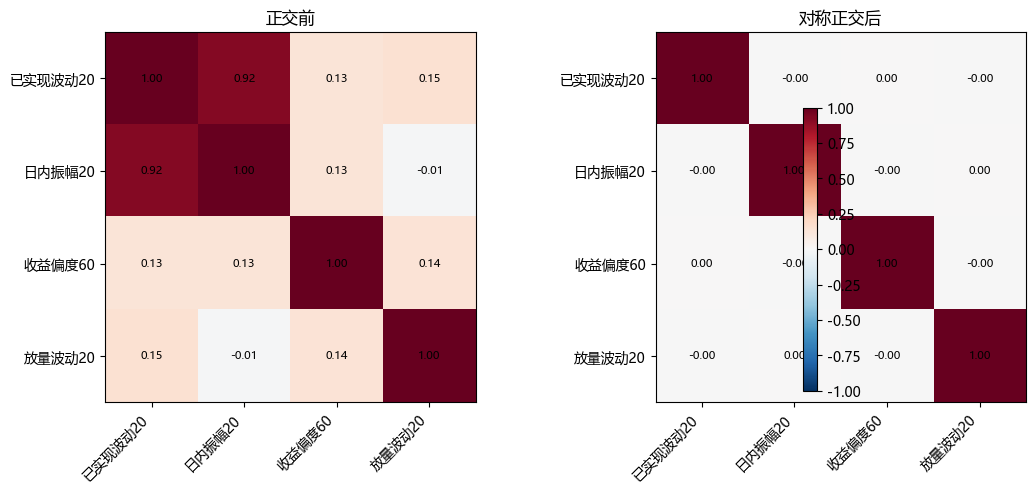

In [4]:
# 热力图：正交前 vs 对称正交后
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, axes = plt.subplots(1, 2, figsize=(11,4.6))
for ax, mat, title in [(axes[0], panel.corr(), '正交前'),
                       (axes[1], sym.corr(), '对称正交后')]:
    im = ax.imshow(mat, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha='right')
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
    ax.set_title(title)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, '%.2f'%mat.values[i,j], ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.8); plt.tight_layout(); plt.show()

## 四、两种正交的区别

- **Gram-Schmidt**：逐个因子正交，结果依赖因子顺序，第一个因子保留全部信息，后续因子依次剥离；
- **对称正交**：F(F^TF)^-1/2，不依赖顺序，各因子信息保留更均衡，Barra 等机构常用；
- 选择：有明确优先级用 Schmidt，要公平对待各因子用对称正交。

## 五、PCA 降维

In [5]:
pca = orthogonal.pca_factors(panel, n_components=4)
evr = pca['explained_variance_ratio']
out = pd.DataFrame({'解释方差比': evr, '累计': np.cumsum(evr)},
                   index=['PC%d'%(i+1) for i in range(4)])
print(out.round(4).to_string())
print()
print('主成分载荷:')
print(pca['loadings'].round(3).to_string())

      解释方差比      累计
PC1  0.4925  0.4925
PC2  0.2747  0.7673
PC3  0.2160  0.9833
PC4  0.0167  1.0000

主成分载荷:
           PC1    PC2    PC3    PC4
已实现波动20  0.692 -0.102  0.119  0.705
日内振幅20   0.681 -0.223 -0.015 -0.698
收益偏度60   0.204  0.620 -0.758  0.017
放量波动20   0.128  0.746  0.642 -0.127


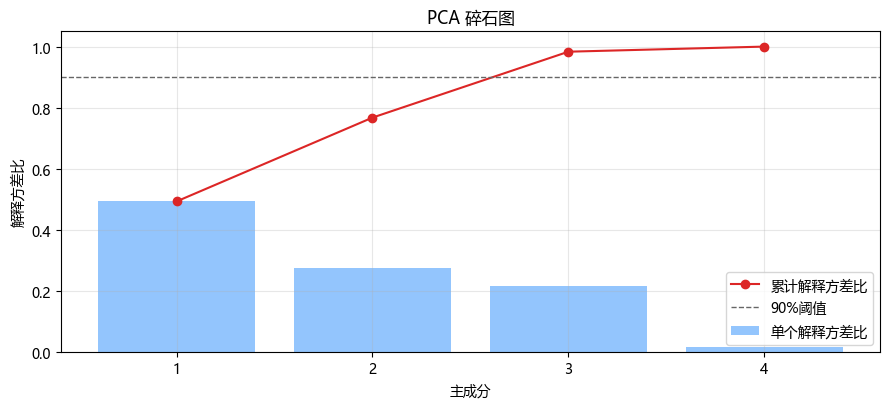

In [6]:
fig, ax = plt.subplots(figsize=(9,4.2))
x = np.arange(1,5)
ax.bar(x, evr, color='#93c5fd', label='单个解释方差比')
ax.plot(x, np.cumsum(evr), 'o-', color='#dc2626', label='累计解释方差比')
ax.axhline(0.9, color='#666', ls='--', lw=1, label='90%阈值')
ax.set_xticks(x); ax.set_xlabel('主成分'); ax.set_ylabel('解释方差比')
ax.set_title('PCA 碎石图'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- PCA 把高相关因子压缩为少数独立主成分，用累计方差比决定保留个数；
- 主成分可直接作为风险因子或降维后的特征，但经济含义不如原因子直观。

## 六、小结与面试要点

- 正交剔除因子冗余：Schmidt 依赖顺序、对称正交不依赖顺序且信息均衡；残差正交针对指定因子。
- PCA 用特征分解降维，碎石图和累计方差比指导保留成分数。

**面试高频：**
- 对称正交和 Schmidt 的区别？（答：前者不依赖顺序、信息均衡，后者逐因子、依赖顺序）
- 为什么要做因子正交？（答：去多重共线性、避免重复计权、利于归因）
- PCA 怎么决定保留几个成分？（答：看累计解释方差，常取80%~90%）
- 正交会改变因子的预测能力吗？（答：信息不丢失，但需重新评估IC，方向可能变化）

## 动手练习
1. 对一组高相关因子做对称正交并验证相关归零；
2. 用 PCA 压缩因子，找到累计方差达 90% 的成分数；
3. 对比正交前后各因子的 IC 是否变化。

---
下一节 **M2.4 因子合成与择时**。